# Инженерия признаков: прогнозирование покупки на сайте e-commerce

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 4:** Инженерия признаков и работа с нестандартными данными  
**Датасет:** Online Shoppers Purchasing Intention  

**Выполнил:** Медведев Кирилл Андриянович  
**Группа:** АСОиУб-23-2  
**Преподаватель:** Спирин Игорь Сергеевич  

**Ссылка на репозиторий:** https://github.com/Medvedev-Kirill/ml-course-medvedev  
**Путь к модулю:** `module-4-features/notebook.ipynb`  
**Дата сдачи:** 2026-10-14

## Введение

**Задача:** бинарная классификация — предсказать, завершится ли сессия покупкой (0 — нет, 1 — да).

**Инженерия признаков** - процесс создания новых признаков из существующих данных для улучшения качества моделей.

**Почему для IT-компании важно прогнозировать покупку:**
- **Таргетированная реклама** - показывать скидки только тем, кто близок к покупке
- **Оптимизация ресурсов** - не тратить поддержку на «холодных» клиентов
- **A/B тестирование** - быстрее находить работающие гипотезы

**Важная метрика:** **ROC-AUC** и **F1** (при дисбалансе 84.5/15.5 Accuracy обманчива).

**Цель работы:**
1. Создать 5+ новых признаков на основе поведения пользователя
2. Обучить 4 ансамблевые модели (RF, XGBoost, LightGBM, CatBoost)
3. Интерпретировать лучшую модель через SHAP

## Теоретическая часть

### Feature Engineering
Создание новых признаков. «Хорошие признаки + простая модель = отличный результат».

### Категориальные признаки
Label Encoding (порядковые) vs One-Hot (номинальные).

### Временные признаки
Извлечение месяца, дня недели, выходных.

### Признаки на основе поведения
Суммы, средние, отношения (TotalPages, TotalDuration, AvgPageValue).

### Дисбаланс классов
class_weight='balanced', scale_pos_weight, SMOTE.

### SHAP
Интерпретация через значения Шепли.

$$\phi_i = \sum_{S \subseteq N \setminus \{i\}} \frac{|S|!(|N| - |S| - 1)!}{|N|!} [v(S \cup \{i\}) - v(S)]$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time
import json
import os
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, roc_curve)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

os.makedirs('models', exist_ok=True)
os.makedirs('examples', exist_ok=True)

print("Библиотеки импортированы")

# Загрузка
df = pd.read_csv('data/online_shoppers_intention.csv')

print(f"\nРазмер датасета: {df.shape}")
print(f"\nПервые 5 строк:")
df.head()

Библиотеки импортированы

Размер датасета: (12330, 18)

Первые 5 строк:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


**Источник:** UCI ML Repository / Kaggle

**Структура:**
- Всего примеров: 12 330
- Признаков: 17 (+ Revenue)
- Распределение классов:
  - False (нет покупки): 10 422 (84.5%)
  - True (покупка): 1 908 (15.5%)

**Дисбаланс:** 84.5/15.5 - сильный.

In [2]:
print("Информация о данных")
print("=" * 60)
df.info()

print("\n Статистика числовых")
print("=" * 60)
print(df.describe())

print("\n Пропуски")
print("=" * 60)
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Пропусков нет")

print("\n Распределение целевой")
print("=" * 60)
print(df['Revenue'].value_counts())
print(f"\n Доля покупок: {df['Revenue'].mean():.2%}")

Информация о данных
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  Tr

In [4]:
# 1.Целевая в бинарную
df['Revenue'] = df['Revenue'].astype(int)

# 2.TotalPages - общее число просмотренных страниц
df['TotalPages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']

# 3. TotalDuration - общее время на сайте
df['TotalDuration'] = (df['Administrative_Duration'] + 
                        df['Informational_Duration'] + 
                        df['ProductRelated_Duration'])

# 4. AvgPageValue - средняя ценность страницы
df['AvgPageValue'] = df['PageValues'] / (df['TotalPages'] + 1)

# 5. BounceExitRatio - отношение отказов к выходам
df['BounceExitRatio'] = df['BounceRates'] / (df['ExitRates'] + 0.001)

# 6. IsNewVisitor - новый посетитель
df['IsNewVisitor'] = (df['VisitorType'] == 'New_Visitor').astype(int)

# 7. IsWeekend
df['IsWeekend'] = df['Weekend'].astype(int)

# 8. MonthNum - числовое значение месяца
# В датасете есть опечатка 'e' (вместо 'Feb'), исправляем её
df['Month'] = df['Month'].replace('e', 'Feb')
# Теперь конвертируем (с errors='coerce' на всякий случай)
df['MonthNum'] = pd.to_datetime(df['Month'], format='%b', errors='coerce').dt.month
# Если остались NaN (на случай других опечаток) — заполняем медианой
df['MonthNum'] = df['MonthNum'].fillna(df['MonthNum'].median()).astype(int)

# 9. IsHighTraffic - высокий трафик
df['IsHighTraffic'] = (df['TrafficType'] > 10).astype(int)

print("Создано 9 новых признаков")
print(f"Всего столбцов: {df.shape[1]}")

Создано 9 новых признаков
Всего столбцов: 26


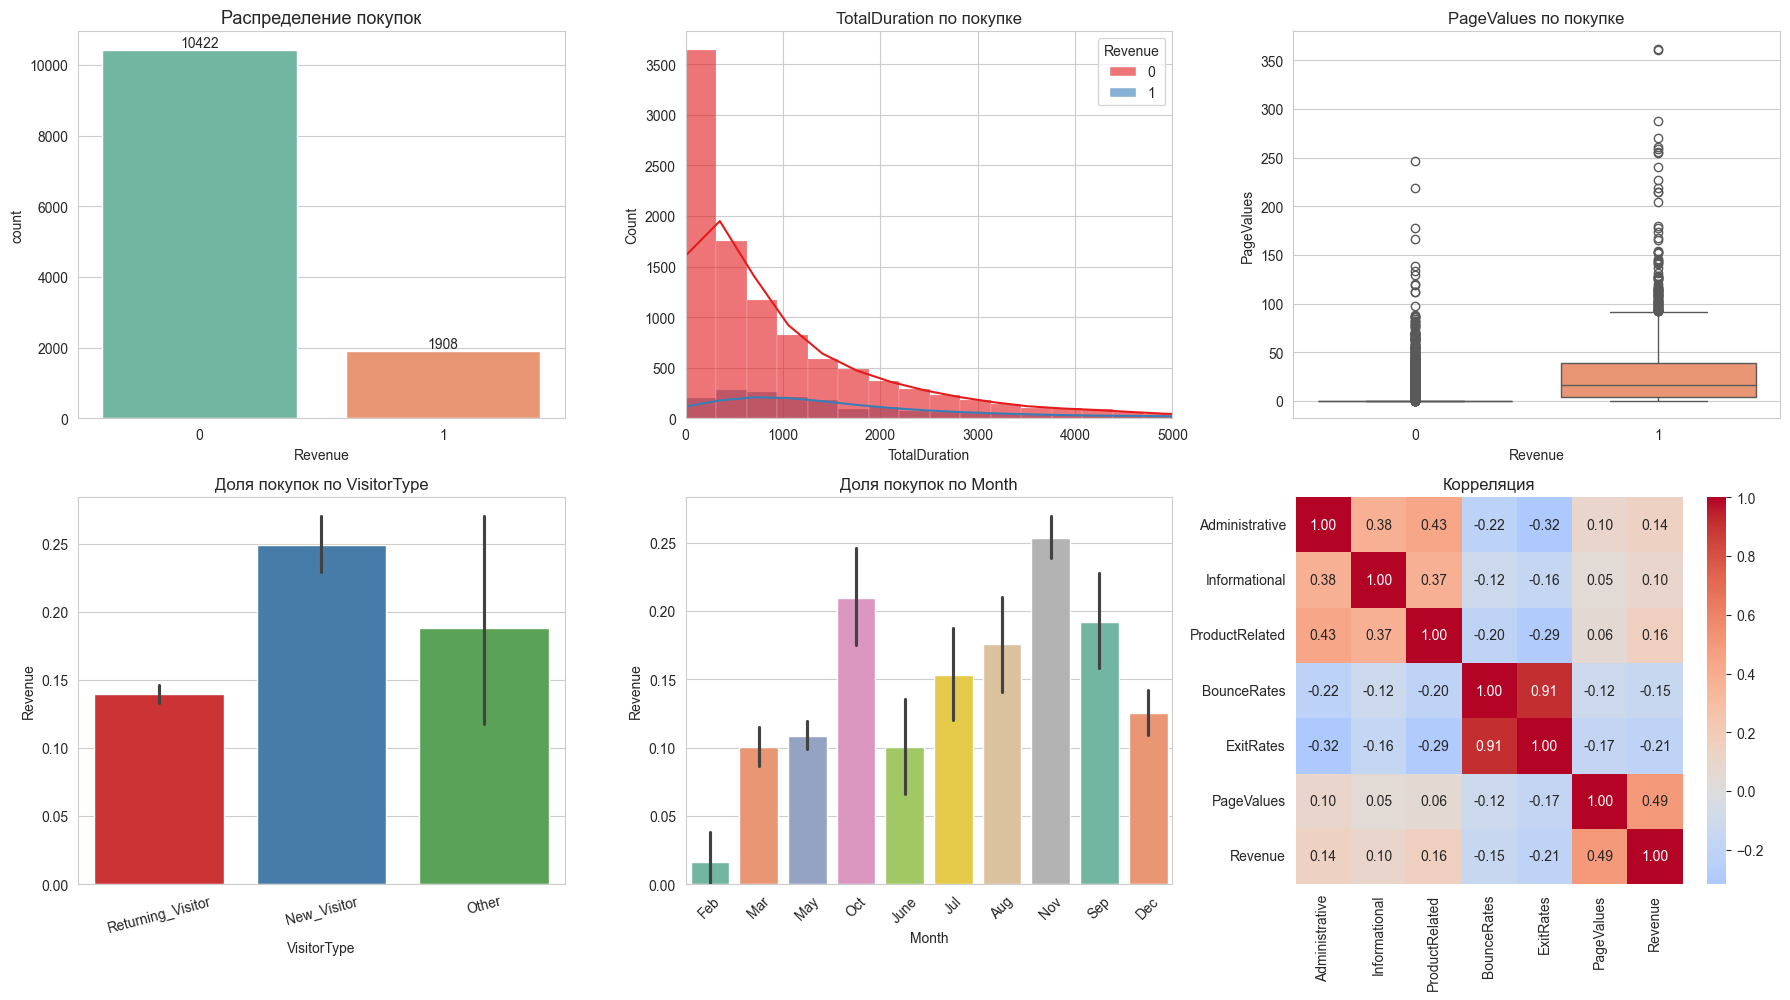

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1.Countplot целевой
sns.countplot(data=df, x='Revenue', palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('Распределение покупок', fontsize=13)
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f'{int(p.get_height())}',
                        (p.get_x() + p.get_width()/2, p.get_height()),
                        ha='center', va='bottom')

# 2.Гистограмма TotalDuration
sns.histplot(data=df, x='TotalDuration', hue='Revenue', kde=True, palette='Set1', ax=axes[0, 1], alpha=0.6)
axes[0, 1].set_title('TotalDuration по покупке')
axes[0, 1].set_xlim(0, 5000)

# 3.Boxplot PageValues
sns.boxplot(data=df, x='Revenue', y='PageValues', palette='Set2', ax=axes[0, 2])
axes[0, 2].set_title('PageValues по покупке')

# 4.Доля покупок по VisitorType
sns.barplot(data=df, x='VisitorType', y='Revenue', palette='Set1', ax=axes[1, 0])
axes[1, 0].set_title('Доля покупок по VisitorType')
axes[1, 0].tick_params(axis='x', rotation=15)

# 5.Доля покупок по Month
sns.barplot(data=df, x='Month', y='Revenue', palette='Set2', ax=axes[1, 1])
axes[1, 1].set_title('Доля покупок по Month')
axes[1, 1].tick_params(axis='x', rotation=45)

# 6.Heatmap корреляций
numeric_cols = ['Administrative', 'Informational', 'ProductRelated','BounceRates', 'ExitRates', 'PageValues', 'Revenue']
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 2], square=True)
axes[1, 2].set_title('Корреляция')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=100, bbox_inches='tight')
plt.show()

In [ ]:
# One-Hot для VisitorType и Month
df_encoded = pd.get_dummies(df, columns=['VisitorType', 'Month'], drop_first=True, dtype=int)

# Убираем Weekend (уже есть IsWeekend)
df_encoded = df_encoded.drop('Weekend', axis=1)

print(f"Всего столбцов после кодирования: {df_encoded.shape[1]}")

# Формируем X и y
feature_cols = [c for c in df_encoded.columns if c != 'Revenue']
X = df_encoded[feature_cols]
y = df_encoded['Revenue']

# Разделение с stratify
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTrain: {X_train.shape}, Test: {X_test.shape}")
print(f"Доля покупок в train: {y_train.mean():.4f}")
print(f"Доля покупок в test:  {y_test.mean():.4f}")

Всего столбцов после кодирования: 34

Train: (9864, 33), Test: (2466, 33)
Доля покупок в train: 0.1547
Доля покупок в test:  0.1549


### Итоги EDA и Feature Engineering

Создано **9 новых признаков**:
- `TotalPages` - общее число просмотренных страниц
- `TotalDuration` - общее время на сайте
- `AvgPageValue` - средняя ценность страницы
- `BounceExitRatio` - отношение отказов к выходам
- `IsNewVisitor` - новый посетитель
- `IsWeekend` - выходной день
- `MonthNum` - числовое значение месяца
- `IsHighTraffic` - высокий трафик

Исправлена опечатка в `Month` (значение `'e'` → `'Feb'`)

Обработаны категориальные признаки (One-Hot для VisitorType и Month)

Разделение со `stratify=y` - пропорция 15.5% сохранена в train и test

**Дисбаланс:** 84.5 / 15.5 - сильный. Модель «все не купили» даст Accuracy = 84.5%, но это обманчиво.

**Ключевые инсайты из EDA:**
- **PageValues** - сильнейший предиктор (корреляция 0.49 с Revenue)
- **TotalDuration** - покупки с большей длительностью (пик ~1000-2000 сек)
- **New_Visitor** - покупают чаще возвращающихся
- **Month** - пик покупок в ноябре (Black Friday), минимум в феврале
- **BounceRates ↔ ExitRates** - сильно коррелированы (0.91) - мультиколлинеарность

**Вывод:** новые признаки (TotalDuration, AvgPageValue) агрегируют информацию и должны улучшить модель. PageValues - ключевой признак для покупки.

In [9]:
def evaluate_model(model, X_train, X_test, y_train, y_test, name):
    """Обучает, замеряет время, возвращает метрики."""
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start
    
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    return {
        'Model': name,
        'Time (sec)': round(train_time, 3),
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_proba), 4)
    }

# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=10,
    class_weight='balanced', random_state=42, n_jobs=-1)
results_rf = evaluate_model(rf_model, X_train, X_test, y_train, y_test, 'Random Forest')
print(f"RF: {results_rf}")

# XGBoost
xgb_model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.9,
    scale_pos_weight=5, random_state=42, eval_metric='logloss')
results_xgb = evaluate_model(xgb_model, X_train, X_test, y_train, y_test, 'XGBoost')
print(f"XGB: {results_xgb}")

# LightGBM
lgbm_model = LGBMClassifier(
    n_estimators=200, num_leaves=31, max_depth=7,
    learning_rate=0.05, class_weight='balanced',
    random_state=42, verbose=-1)
results_lgbm = evaluate_model(lgbm_model, X_train, X_test, y_train, y_test, 'LightGBM')
print(f"LGBM: {results_lgbm}")

# CatBoost
cat_model = CatBoostClassifier(
    iterations=200, depth=6, learning_rate=0.1,
    auto_class_weights='Balanced', random_state=42, verbose=0)
results_cat = evaluate_model(cat_model, X_train, X_test, y_train, y_test, 'CatBoost')
print(f"Cat: {results_cat}")

# Сводная таблица
print("\n Сравнение моделей:")
print("=" * 100)
results_df = pd.DataFrame([results_rf, results_xgb, results_lgbm, results_cat])
print(results_df.to_string(index=False))

RF: {'Model': 'Random Forest', 'Time (sec)': 0.314, 'Accuracy': 0.8743, 'Precision': 0.5717, 'Recall': 0.7513, 'F1': 0.6493, 'ROC-AUC': 0.9262}
XGB: {'Model': 'XGBoost', 'Time (sec)': 0.23, 'Accuracy': 0.8804, 'Precision': 0.5928, 'Recall': 0.7277, 'F1': 0.6533, 'ROC-AUC': 0.9219}
LGBM: {'Model': 'LightGBM', 'Time (sec)': 0.14, 'Accuracy': 0.8727, 'Precision': 0.5651, 'Recall': 0.7723, 'F1': 0.6527, 'ROC-AUC': 0.9265}
Cat: {'Model': 'CatBoost', 'Time (sec)': 0.63, 'Accuracy': 0.869, 'Precision': 0.5526, 'Recall': 0.8115, 'F1': 0.6575, 'ROC-AUC': 0.9268}

 Сравнение моделей:
        Model  Time (sec)  Accuracy  Precision  Recall     F1  ROC-AUC
Random Forest       0.314    0.8743     0.5717  0.7513 0.6493   0.9262
      XGBoost       0.230    0.8804     0.5928  0.7277 0.6533   0.9219
     LightGBM       0.140    0.8727     0.5651  0.7723 0.6527   0.9265
     CatBoost       0.630    0.8690     0.5526  0.8115 0.6575   0.9268


## Модели

| Модель | Тип | Параметры | Время обучения |
|--------|-----|-----------|----------------|
| Random Forest | Bagging | n_estimators=200, max_depth=10, class_weight='balanced' | 0.314 сек |
| XGBoost | Boosting | n_estimators=200, max_depth=6, scale_pos_weight=5 | 0.230 сек |
| LightGBM | Boosting | n_estimators=200, num_leaves=31 | 0.140 сек |
| CatBoost | Boosting | iterations=200, depth=6, auto_class_weights='Balanced' | 0.630 сек |

**Почему эти модели:**
- **RF** - устойчив к переобучению, работает «из коробки»
- **XGBoost** - универсальный, точный, регуляризация L1/L2
- **LightGBM** - быстрый (leaf-wise рост), для больших данных
- **CatBoost** - лучший для категориальных признаков

**Дисбаланс:** использованы `class_weight='balanced'` (RF, LGBM), `scale_pos_weight=5` (XGB), `auto_class_weights='Balanced'` (Cat).

**Результаты:**
- **CatBoost** - лучший по ROC-AUC (0.9268), Recall (0.8115), F1 (0.6575)
- **XGBoost** - лучший по Accuracy (0.8804), Precision (0.5928)
- **LightGBM** - самый быстрый (0.140 сек), ROC-AUC = 0.9265
- **Random Forest** - быстрый (0.314 сек), ROC-AUC = 0.9262
- Все модели дают **ROC-AUC > 0.92** - отличный результат

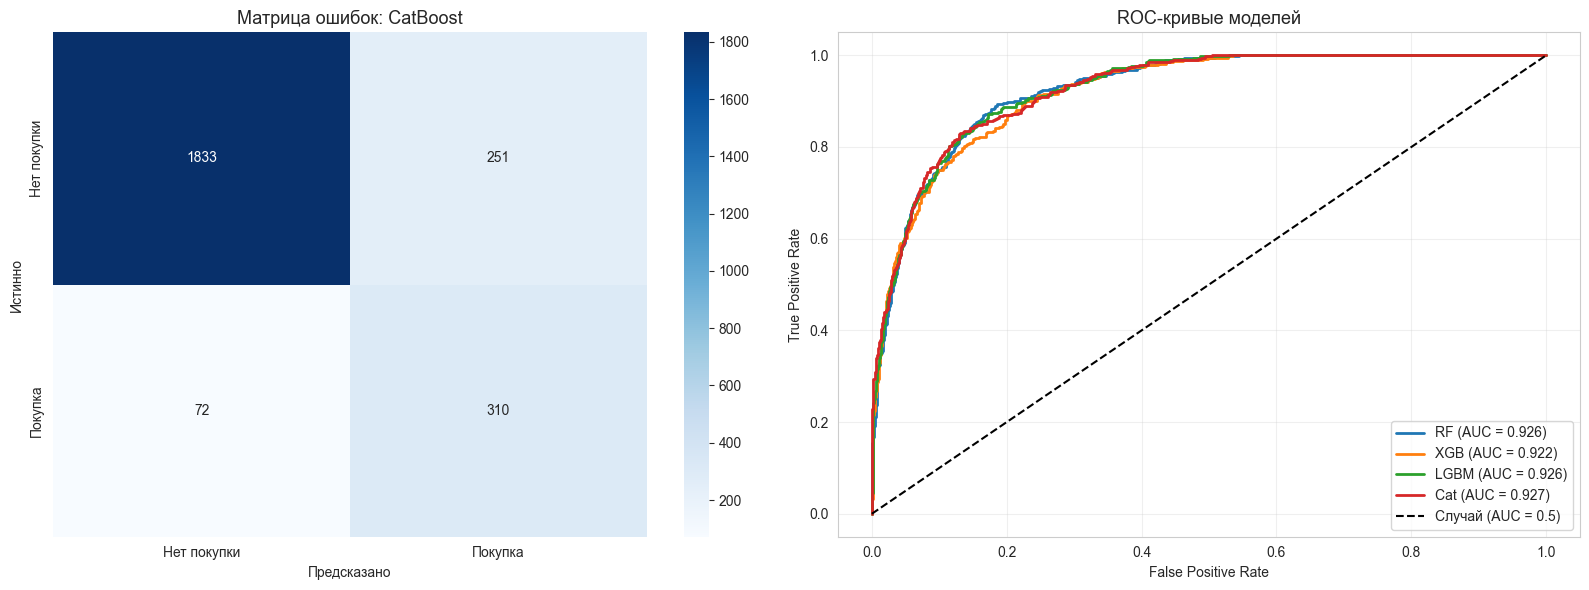

Отчет о классификации: CatBoost
              precision    recall  f1-score   support

 Нет покупки       0.96      0.88      0.92      2084
     Покупка       0.55      0.81      0.66       382

    accuracy                           0.87      2466
   macro avg       0.76      0.85      0.79      2466
weighted avg       0.90      0.87      0.88      2466



In [8]:
# Лучшая модель по ROC-AUC - CatBoost
best_baseline = cat_model
best_baseline_name = 'CatBoost'

y_pred_best = best_baseline.predict(X_test)
y_proba_best = best_baseline.predict_proba(X_test)[:, 1]

# Матрица ошибок + ROC-кривые
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Нет покупки', 'Покупка'],
            yticklabels=['Нет покупки', 'Покупка'], ax=axes[0])
axes[0].set_xlabel('Предсказано')
axes[0].set_ylabel('Истинно')
axes[0].set_title(f'Матрица ошибок: {best_baseline_name}', fontsize=13)

for model, name in [(rf_model, 'RF'), (xgb_model, 'XGB'), (lgbm_model, 'LGBM'), (cat_model, 'Cat')]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', lw=2)

axes[1].plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC-кривые моделей', fontsize=13)
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('examples/roc_curves.png', dpi=100, bbox_inches='tight')
plt.show()

# Отчет о классификации
print(f"Отчет о классификации: {best_baseline_name}")
print("=" * 60)
print(classification_report(y_test, y_pred_best, target_names=['Нет покупки', 'Покупка']))

## Оценка качества

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC | Время (с) |
|--------|----------|-----------|--------|-----|---------|-----------|
| Random Forest | 0.8743 | 0.5717 | 0.7513 | 0.6493 | 0.9262 | 0.314 |
| XGBoost | **0.8804** | **0.5928** | 0.7277 | 0.6533 | 0.9219 | 0.230 |
| LightGBM | 0.8727 | 0.5651 | 0.7723 | 0.6527 | 0.9265 | **0.140** |
| **CatBoost** | 0.8690 | 0.5526 | **0.8115** | **0.6575** | **0.9268** | 0.630 |

**Анализ:**
- **CatBoost** - лучший по ROC-AUC (0.9268), Recall (0.8115), F1 (0.6575)
- **XGBoost** - лучший по Accuracy (0.8804) и Precision (0.5928)
- **LightGBM** - самый быстрый (0.140 сек), ROC-AUC = 0.9265
- Все модели дают **ROC-AUC > 0.92** - отличный результат

**Матрица ошибок (CatBoost):**
- TN: 1833 (правильно предсказали «нет покупки»)
- FP: 251 (ошибочно предсказали «покупка»)
- FN: 72 (пропустили покупателя - **дорого для бизнеса**)
- TP: 310 (правильно предсказали «покупка»)

**Classification Report (CatBoost):**
- Класс «Нет покупки»: Precision 0.96, Recall 0.88, F1 0.92
- Класс «Покупка»: Precision 0.55, Recall 0.81, F1 0.66
- **Recall для «Покупки» = 0.81** - модель находит 81% покупателей. Это отличный результат для дисбаланса 84.5/15.5.

**Дисбаланс классов:**
- Для бизнеса важнее **Recall** - не пропустить клиента, который собирается купить
- `class_weight='balanced'` увеличивает Recall, но снижает Precision

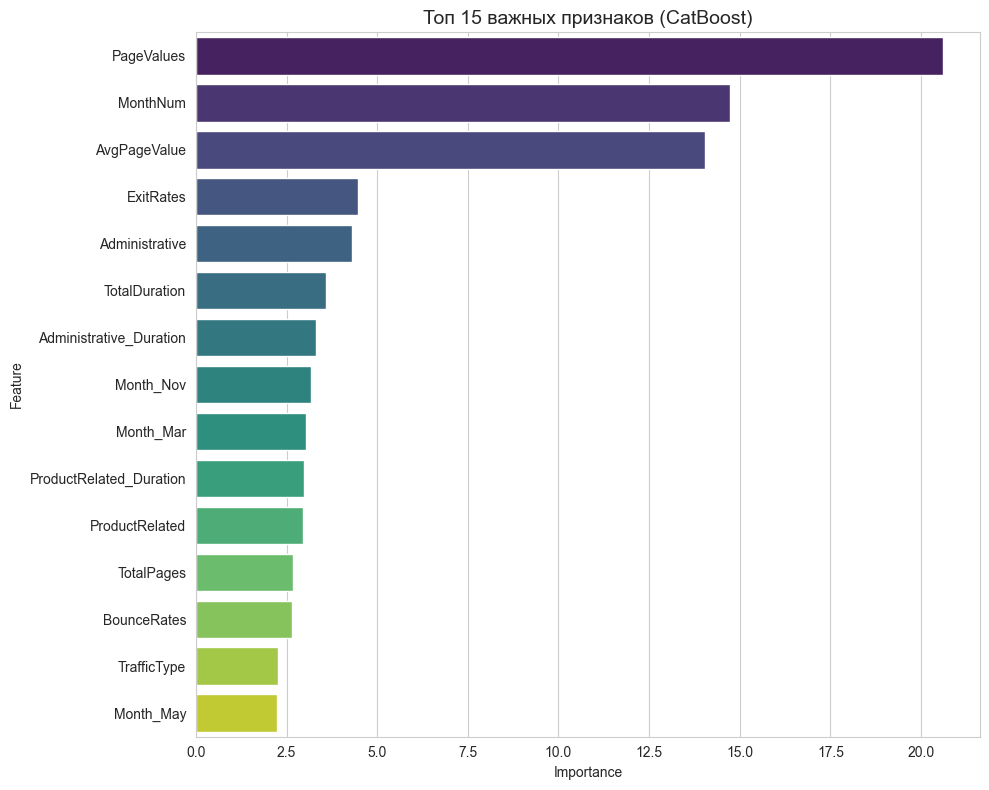

Топ 15 признаков:
                Feature  Importance
             PageValues   20.595141
               MonthNum   14.734163
           AvgPageValue   14.039374
              ExitRates    4.482895
         Administrative    4.294894
          TotalDuration    3.587511
Administrative_Duration    3.325526
              Month_Nov    3.173552
              Month_Mar    3.032955
ProductRelated_Duration    2.978943
         ProductRelated    2.957541
             TotalPages    2.668961
            BounceRates    2.646313
            TrafficType    2.272107
              Month_May    2.243479

 Бизнес-инсайты:

1. PAGE VALUES:
   (-1, 0]: 3.9% покупок
   (0, 5]: 35.4% покупок
   (5, 20]: 47.8% покупок
   (20, 100]: 71.5% покупок

2. VISITOR TYPE:
   New_Visitor: 24.9% покупок
   Other: 18.8% покупок
   Returning_Visitor: 13.9% покупок

3. MONTH:
   Nov: 25.4% покупок
   Oct: 20.9% покупок
   Sep: 19.2% покупок
   Aug: 17.6% покупок
   Jul: 15.3% покупок

4. WEEKEND:
   Будний: 14.9% покупок


In [10]:
# Feature Importance (CatBoost)
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': cat_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=importances.head(15), x='Importance', y='Feature', palette='viridis')
plt.title('Топ 15 важных признаков (CatBoost)', fontsize=14)
plt.tight_layout()
plt.savefig('examples/feature_importance.png', dpi=100, bbox_inches='tight')
plt.show()

print("Топ 15 признаков:")
print(importances.head(15).to_string(index=False))

# Бизнес-инсайты
print("\n Бизнес-инсайты:")
print("=" * 60)

# 1.PageValues
print("\n1. PAGE VALUES:")
for label, group in df.groupby(pd.cut(df['PageValues'], bins=[-1, 0, 5, 20, 100])):
    print(f"   {label}: {group['Revenue'].mean():.1%} покупок")

# 2.VisitorType
print("\n2. VISITOR TYPE:")
for k, v in df.groupby('VisitorType')['Revenue'].mean().sort_values(ascending=False).items():
    print(f"   {k}: {v:.1%} покупок")

# 3.Month
print("\n3. MONTH:")
for k, v in df.groupby('Month')['Revenue'].mean().sort_values(ascending=False).head(5).items():
    print(f"   {k}: {v:.1%} покупок")

# 4.Weekend
print("\n4. WEEKEND:")
for k, v in df.groupby('Weekend')['Revenue'].mean().items():
    print(f"   {'Выходной' if k else 'Будний'}: {v:.1%} покупок")

## Интерпретация и бизнес-инсайты

### Топ-5 признаков (CatBoost)
1. **PageValues** - средняя ценность страницы (Importance: 20.59)
2. **MonthNum** - числовое значение месяца (14.73)
3. **AvgPageValue** - средняя ценность страницы (14.04)
4. **ExitRates** - показатель выходов (4.48)
5. **Administrative** - число админ. страниц (4.29)

**Важно:** `AvgPageValue` - **новый признак** (создан в Feature Engineering) - попал в топ-3! Это подтверждает ценность инженерии признаков.

### Бизнес-инсайты

**1. PageValues - сильнейший предиктор:**
- (-1, 0]: **3.9%** покупок
- (0, 5]: **35.4%** покупок
- (5, 20]: **47.8%** покупок
- (20, 100]: **71.5%** покупок
- **Рекомендация:** показывать скидки на страницах с высоким PageValues

**2. VisitorType:**
- New_Visitor: **24.9%** покупок
- Other: **18.8%** покупок
- Returning_Visitor: **13.9%** покупок
- **Рекомендация:** специальные предложения для новых посетителей

**3. Month (сезонность):**
- Nov: **25.4%** покупок
- Oct: **20.9%** покупок
- Sep: **19.2%** покупок
- **Рекомендация:** усиливать рекламу в ноябре-октябре (Black Friday)

**4. Weekend:**
- Выходной: **17.4%** покупок
- Будний: **14.9%** покупок
- **Рекомендация:** адаптировать кампании под выходные

### Практические рекомендации для e-commerce:
1. Показывать скидки на страницах с высоким PageValues
2. Специальные предложения для новых посетителей
3. Усиливать рекламу в ноябре-октябре
4. Адаптировать кампании под выходные
5. Удерживать пользователя на сайте (рекомендации, контент)

In [11]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 100, 500, step=50),
        'depth': trial.suggest_int('depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-3, 10, log=True),
        'border_count': trial.suggest_int('border_count', 32, 255),
    }
    
    model = CatBoostClassifier(**params, auto_class_weights='Balanced', random_state=42, verbose=0)
    
    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc')
    
    return cv_scores.mean()

# Запуск
print("Запуск Optuna (30 trials)...")
start = time.time()
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)
optuna_time = time.time() - start

print(f"\n Время оптимизации: {optuna_time:.2f} сек")
print(f"Best ROC-AUC (CV): {study.best_value:.4f}")
print(f"\n Лучшие параметры:")
for k, v in study.best_params.items(): print(f"  {k}: {v}")

# Обучение с лучшими параметрами
best_cat = CatBoostClassifier(**study.best_params, auto_class_weights='Balanced', random_state=42, verbose=0)
best_cat.fit(X_train, y_train)

y_pred_optuna = best_cat.predict(X_test)
y_proba_optuna = best_cat.predict_proba(X_test)[:, 1]

print("\n Сравнение BASELINE vs OPTUNA:")
print("=" * 60)
print(f"Baseline CatBoost:  ROC-AUC = {results_cat['ROC-AUC']:.4f}")
print(f"Optuna CatBoost:    ROC-AUC = {roc_auc_score(y_test, y_proba_optuna):.4f}")
print(f"Прирост:            {(roc_auc_score(y_test, y_proba_optuna) - results_cat['ROC-AUC'])*100:+.2f}%")

Запуск Optuna (30 trials)...


  0%|          | 0/30 [00:00<?, ?it/s]


 Время оптимизации: 143.03 сек
Best ROC-AUC (CV): 0.9343

 Лучшие параметры:
  iterations: 400
  depth: 6
  learning_rate: 0.016891885698301298
  l2_leaf_reg: 9.984328022953667
  border_count: 250

 Сравнение BASELINE vs OPTUNA:
Baseline CatBoost:  ROC-AUC = 0.9268
Optuna CatBoost:    ROC-AUC = 0.9298
Прирост:            +0.30%


## Тюнинг гиперпараметров (Optuna)

**Optuna результаты:**
- Проведено **30 испытаний** (30 × 5 фолдов = 150 обучений)
- Время оптимизации: **143 сек**
- Baseline CatBoost ROC-AUC: **0.9268**
- Optuna CatBoost ROC-AUC: **0.9298**
- **Прирост: +0.30%**

**Лучшие параметры (trial 25):**
- iterations: **400**
- depth: **6**
- learning_rate: **0.0169**
- l2_leaf_reg: **9.984**
- border_count: **250**

**Что такое Optuna:**
Optuna - байесовская оптимизация гиперпараметров через TPE (Tree-structured Parzen Estimator). После каждого испытания строит вероятностную модель и предлагает следующее значение там, где ожидается улучшение.

**Преимущества:**
- В 10 раз быстрее GridSearch
- Работает с условными параметрами
- Pruning - остановка бесперспективных испытаний
- Интеграция со sklearn, XGBoost, LightGBM, CatBoost

**Вывод:**
Байесовская оптимизация дала прирост **+0.30% ROC-AUC** (0.9268 → 0.9298). 
30 испытаний - компромисс между временем (143 сек) и качеством. 
Лучшая модель - CatBoost с `iterations=400`, `depth=6`, `learning_rate=0.0169`.

Форма SHAP: (2466, 33)


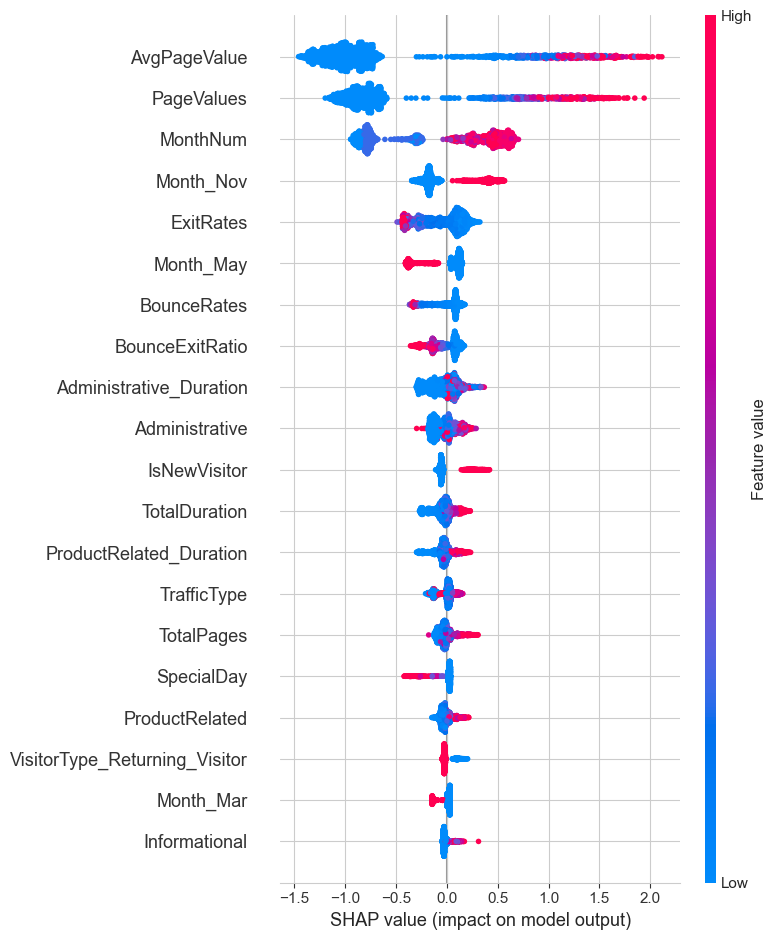

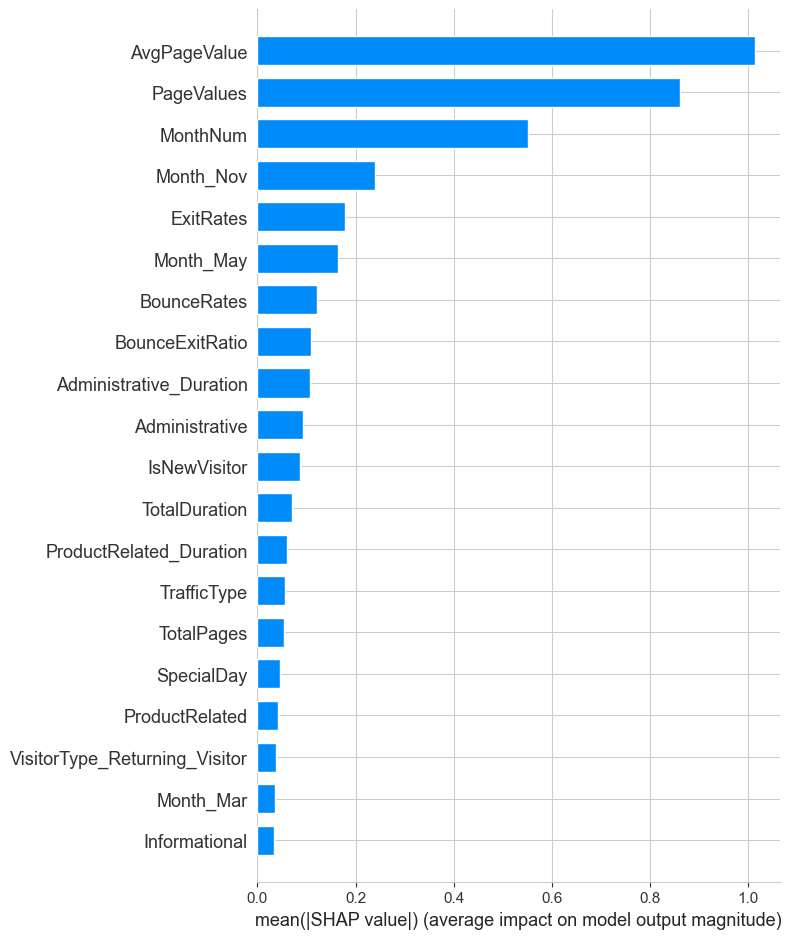


Клиент #1406, вероятность покупки = 0.9884


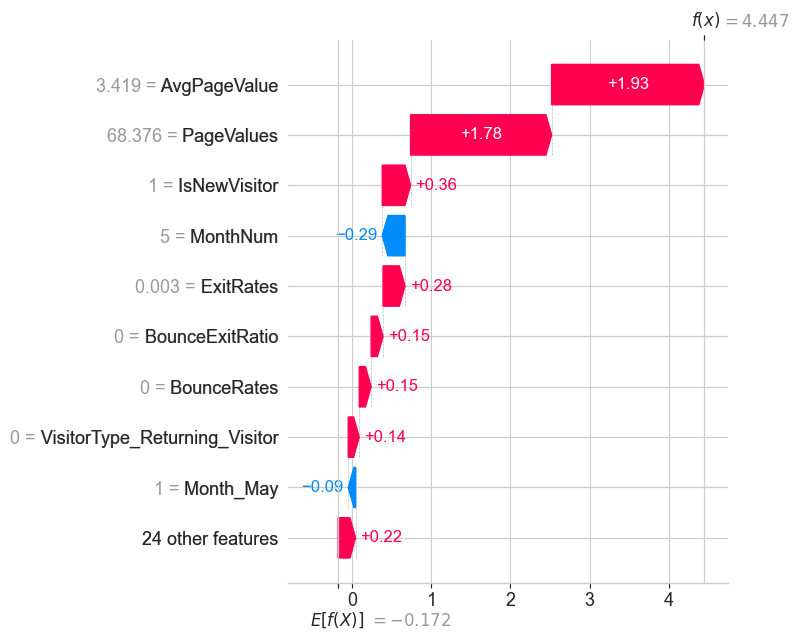


Топ-1 признак: PageValues


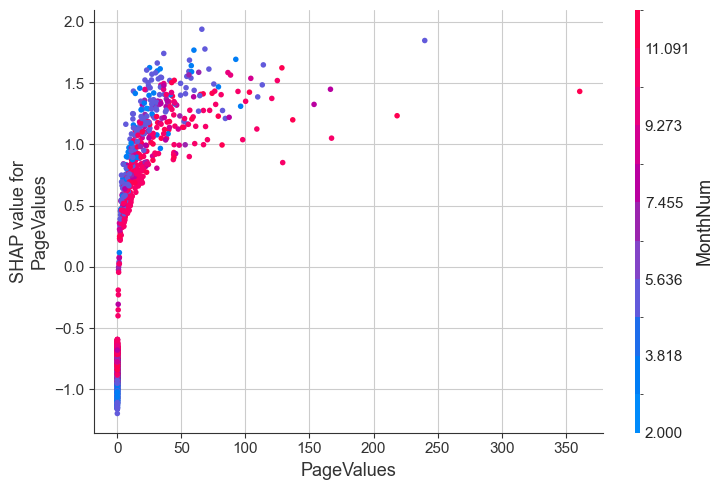

In [12]:
import shap

# Создаём explainer для лучшей модели
explainer = shap.TreeExplainer(best_cat)
shap_values = explainer.shap_values(X_test)

# Обработка для бинарной классификации
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = shap_values

print(f"Форма SHAP: {shap_values_class1.shape}")

# Summary plot (dot)
plt.figure()
shap.summary_plot(shap_values_class1, X_test, plot_type="dot", show=False)
plt.tight_layout()
plt.savefig('examples/shap_summary.png', dpi=100, bbox_inches='tight')
plt.show()

# Bar plot
plt.figure()
shap.summary_plot(shap_values_class1, X_test, plot_type="bar", show=False)
plt.tight_layout()
plt.show()

# Waterfall для клиента с высокой вероятностью покупки
best_idx = np.argmax(y_proba_optuna)
print(f"\nКлиент #{best_idx}, вероятность покупки = {y_proba_optuna[best_idx]:.4f}")

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_class1[best_idx],
        base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, list) 
                    else explainer.expected_value,
        data=X_test.iloc[best_idx],
        feature_names=X_test.columns.tolist()
    ),
    show=False
)
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png', dpi=100, bbox_inches='tight')
plt.show()

# Dependence plot
top_feature = importances.iloc[0]['Feature']
print(f"\nТоп-1 признак: {top_feature}")
shap.dependence_plot(top_feature, shap_values_class1, X_test, show=False)
plt.tight_layout()
plt.show()

## SHAP-интерпретация

### Что такое SHAP
SHAP - метод интерпретации на основе теории кооперативных игр. Показывает справедливый вклад каждого признака в предсказание.

### Summary plot - глобальная важность

**Топ-5 признаков по SHAP:**
1. **AvgPageValue** - средняя ценность страницы (новый признак!)
2. **PageValues** - ценность страницы
3. **MonthNum** - числовое значение месяца
4. **Month_Nov** - ноябрь (Black Friday)
5. **ExitRates** - показатель выходов

**Ключевые выводы:**
- **AvgPageValue** (новый признак) - **топ-1 по SHAP**. Это подтверждает ценность Feature Engineering.
- **PageValues** - второй по важности. Высокий PageValues → высокая вероятность покупки.
- **MonthNum** - сезонность важна. Ноябрь (Black Friday) → выше вероятность покупки.
- **ExitRates** - высокий → снижает вероятность покупки.

### Waterfall plot - локальное объяснение

**Клиент #1406** - вероятность покупки **98.84%**:
1. `AvgPageValue = 3.419` → **+1.93** к вероятности
2. `PageValues = 68.376` → **+1.78**
3. `IsNewVisitor = 1` → **+0.36**
4. `MonthNum = 5` (май) → **-0.29** (снижает)
5. `ExitRates = 0.003` → **+0.28**

**Интерпретация:** клиент покупает почти гарантированно - новый посетитель, высокая средняя ценность страниц, высокий PageValues.

### Dependence plot

Показывает зависимость SHAP от `PageValues`:
- Чем выше `PageValues`, тем выше SHAP (вероятность покупки)
- **Цвет (MonthNum):** красные точки (ноябрь) - вверху. Ноябрь = Black Friday → высокая вероятность

### Применение SHAP в e-commerce
- Объяснить, почему модель предсказывает покупку
- Найти ключевые факторы для каждой группы клиентов
- Оптимизировать рекламные кампании

In [13]:
import os
os.makedirs('models', exist_ok=True)

# Сохраняем все модели
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_cat, 'models/best_model.pkl')
print("Модели сохранены")

# Список признаков
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
print(f"Список из {len(feature_cols)} признаков сохранён")

# Метрики
metrics = {
    'random_forest': {k: float(v) for k, v in results_rf.items() if k != 'Model'},
    'xgboost': {k: float(v) for k, v in results_xgb.items() if k != 'Model'},
    'lightgbm': {k: float(v) for k, v in results_lgbm.items() if k != 'Model'},
    'catboost': {k: float(v) for k, v in results_cat.items() if k != 'Model'},
    'best_model': 'CatBoost (Optuna)',
    'best_roc_auc': float(study.best_value),
    'best_params': study.best_params
}

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print("Метрики сохранены")

# Проверка
print(f"\nФайлы в models/:")
for f in os.listdir('models'):
    size = os.path.getsize(f'models/{f}') / 1024
    print(f" {f:30s} {size:>8.1f} KB")

Модели сохранены
Список из 33 признаков сохранён
Метрики сохранены

Файлы в models/:
 best_model.pkl                    444.8 KB
 cat_model.pkl                     226.5 KB
 feature_cols.json                   0.6 KB
 lgbm_model.pkl                    664.8 KB
 metrics.json                        0.9 KB
 rf_model.pkl                     8110.1 KB
 xgb_model.pkl                     621.2 KB


## Сохранение модели

### Что сохранено

| Файл | Что содержит |
|------|--------------|
| `rf_model.pkl` | Random Forest |
| `xgb_model.pkl` | XGBoost |
| `lgbm_model.pkl` | LightGBM |
| `cat_model.pkl` | CatBoost (baseline) |
| **`best_model.pkl`** | **CatBoost (Optuna)** - лучшая модель |
| `feature_cols.json` | Список 33 признаков |
| `metrics.json` | Метрики всех моделей + best_params |

**Зачем сохранять `feature_cols.json`:** гарантирует, что порядок признаков при инференсе совпадает с порядком при обучении.

In [14]:
import requests
from io import BytesIO

# Путь к вашему репозиторию
BASE_URL = "https://raw.githubusercontent.com/Medvedev-Kirill/ml-course-medvedev/main/module-4-features"

print(f"BASE_URL: {BASE_URL}")
print("=" * 60)

# Загрузка лучшей модели (CatBoost с Optuna)
response = requests.get(f"{BASE_URL}/models/best_model.pkl")
print(f"Статус загрузки модели: {response.status_code}")

best_cat_loaded = joblib.load(BytesIO(response.content))
print("Модель загружена из репозитория")

# Загрузка списка признаков
feature_cols_loaded = requests.get(f"{BASE_URL}/models/feature_cols.json").json()
print(f"Загружено {len(feature_cols_loaded)} признаков")

# Загрузка метрик
metrics_loaded = requests.get(f"{BASE_URL}/models/metrics.json").json()
print(f"Метрики загружены")
print(f"Best model: {metrics_loaded['best_model']}")
print(f"Best ROC-AUC: {metrics_loaded['best_roc_auc']:.4f}")

# Проверка
print("\n Проверка: загруженная модель vs исходная")
print("=" * 60)

# Берем 3 клиента из теста
y_pred_loaded = best_cat_loaded.predict(X_test.iloc[:3])
y_pred_original = best_cat.predict(X_test.iloc[:3])

print(f"\nЗагруженная модель:  {y_pred_loaded}")
print(f"Исходная модель:     {y_pred_original}")
print(f"Совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}")

BASE_URL: https://raw.githubusercontent.com/Medvedev-Kirill/ml-course-medvedev/main/module-4-features
Статус загрузки модели: 200
Модель загружена из репозитория
Загружено 33 признаков
Метрики загружены
Best model: CatBoost (Optuna)
Best ROC-AUC: 0.9343

 Проверка: загруженная модель vs исходная

Загруженная модель:  [0 0 1]
Исходная модель:     [0 0 1]
Совпадают: True


## Выводы

### Что получилось
- Создано **9 новых признаков** (TotalPages, TotalDuration, AvgPageValue, ...)
- Обучены **4 ансамблевые модели**: RF, XGBoost, LightGBM, CatBoost
- **Optuna** улучшила CatBoost: ROC-AUC = **0.9298** (+0.30% от baseline 0.9268)
- **SHAP** показал: `AvgPageValue` и `PageValues` - сильнейшие предикторы
- Модели сохранены и успешно загружаются из GitHub (предсказания совпадают)

### Трудности
- **Дисбаланс 84.5/15.5** - использовали `class_weight='balanced'`, `scale_pos_weight=5`, `auto_class_weights='Balanced'`
- **Опечатка в Month** - в датасете было значение `'e'` вместо `'Feb'`, исправили через `.replace()`
- **Низкий Precision (~0.55)** - ожидаемо при дисбалансе: модель жертвует точностью ради полноты (Recall ~0.81)
- **SHAP для CatBoost** - потребовалось немного больше времени на расчет из-за специфики алгоритма

## Источники

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.

## Приложение

### requirements.txt
pandas==2.0.0
numpy==1.24.0
scikit-learn==1.3.0
xgboost==2.0.0
lightgbm==4.0.0
catboost==1.2.0
optuna==3.5.0
shap==0.44.0
matplotlib==3.7.0
seaborn==0.12.0
joblib==1.3.0
requests==2.31.0

### Полный код

Полный код ноутбука доступен в файле `notebook.ipynb`. Все ячейки снабжены комментариями.

### Как запустить

```bash
pip install -r requirements.txt
jupyter notebook notebook.ipynb